<a href="https://colab.research.google.com/github/dpalma1996/Derian_Palma_Q-Data-Analytics-2026-2027/blob/main/NovaFab_2025_DerianPalmaQuir%C3%B3s.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NovaFab Components | Producción, paradas y calidad
**Análisis de operaciones · 2025**

Como Ingeniero en Mecatrónica, empezaría por distinguir el ritmo de una máquina mientras produce del tiempo que pierde cuando se detiene. Mi hipótesis es que las máquinas que requieren más mantenimiento correctivo también acumulan más paro durante la producción. Voy a contrastarla con los registros de 2025 y después revisaré la calidad de lo fabricado.

### ¿Qué información traen los cinco archivos?
Coloca los cinco CSV en el directorio de trabajo o cambia `carpeta` en la primera celda. Leo los valores como texto para ver su formato original. En calidad, `None` significa que la muestra del lote no presentó defectos.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
carpeta = Path(".")
nombres = ["machines", "products", "production_runs", "quality_checks", "maintenance"]
tablas = {n: pd.read_csv(carpeta / f"{n}.csv", dtype=str, keep_default_na=False) for n in nombres}
maquinas, productos, lotes, controles, mantenimiento = [tablas[n] for n in nombres]

for nombre, tabla in tablas.items():
    print(f"\n{nombre} · {len(tabla):,} filas · {tabla.shape[1]} columnas")
    print(tabla.head(2).to_string(index=False))


machines · 36 filas · 4 columnas
machine_id production_line installation_year rated_units_hour
      M001          Line B              2015            119.5
      M002          Line A              2015            111.0

products · 30 filas · 4 columnas
product_id product_family complexity_level target_cycle_min
      P001       Standard              Low             0.79
      P002      Precision             High             1.35

production_runs · 9,000 filas · 8 columnas
run_id machine_id product_id      start_datetime   shift units_produced runtime_hours downtime_minutes
R00001       M028       P023 2025-07-19 16:32:00 Evening            218          7.68                5
R00002       M017       P004 2025-01-25 11:38:00 Morning            173          4.37                5

quality_checks · 9,000 filas · 4 columnas
run_id units_inspected defective_units defect_severity
R00001              75               1           Minor
R00002              32               1           Minor

main

### ¿Cómo sigo el mismo lote entre tablas?
La primera muestra ya permite seguir un caso. El lote `R00001` produjo 218 unidades. Su control registra 75 inspeccionadas y una defectuosa. Son dos vistas del mismo lote. El inventario reúne 36 máquinas y el catálogo, 30 productos. Los 516 partes de mantenimiento se registran por máquina.

En `production_runs`, cada fila es un lote. Su `machine_id` lleva a la línea en `machines`, su `product_id` lleva al ciclo objetivo en `products` y su `run_id` identifica su inspección en `quality_checks`. Un registro de `maintenance` describe una intervención en una máquina. Una máquina puede tener muchos lotes y varias intervenciones.

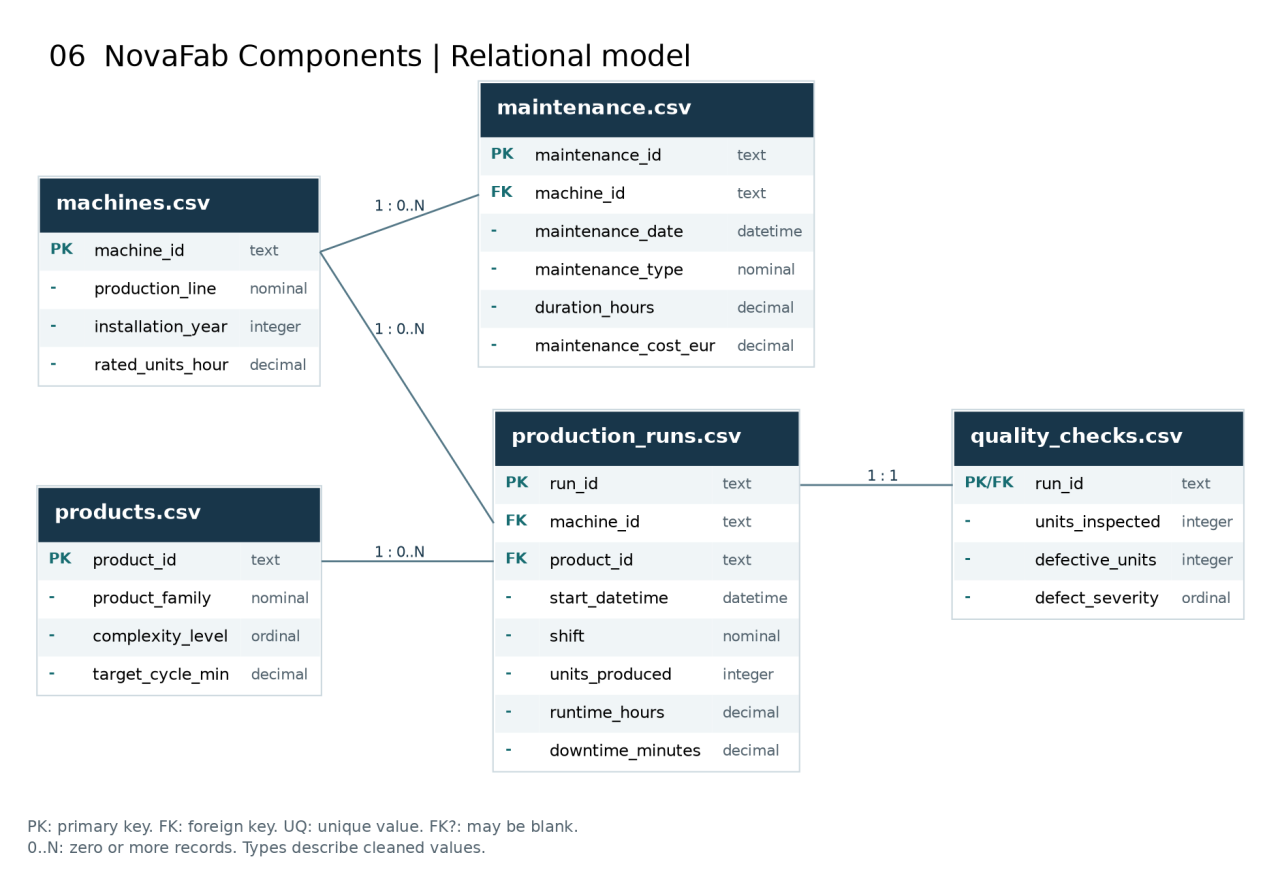

In [2]:
#@title Modelo relacional de NovaFab
from base64 import b64decode
from io import BytesIO
from PIL import Image
from IPython.display import display

# Copia incrustada del archivo relational_model.webp
modelo_webp = b64decode("...")
with Image.open(BytesIO(modelo_webp)) as modelo:
    display(modelo.convert("RGB"))


### ¿Qué formatos necesito corregir?
Antes de contar categorías o sumar horas, miro qué etiquetas parecen distintas por su escritura y qué números o fechas aparecen en dos formatos. Las comillas de la salida hacen visibles los espacios finales.

In [3]:
categorias = [(lotes, "shift"), (productos, "product_family"), (mantenimiento, "maintenance_type")]
for tabla, columna in categorias:
    print(columna, sorted(tabla[columna].unique()))

campos = [(lotes, "runtime_hours", ","), (mantenimiento, "maintenance_cost_eur", ","),
          (lotes, "start_datetime", "/"), (mantenimiento, "maintenance_date", "/")]
for tabla, columna, marca in campos:
    serie = tabla[columna]
    distinto = serie.str.contains(marca)
    print(columna, "· dos formatos:", serie[~distinto].iloc[0], "|", serie[distinto].iloc[0],
          "· filas con", repr(marca), "=", distinto.sum())

shift ['Evening', 'Evening ', 'Morning', 'Morning ', 'Night', 'Night ', 'evening', 'morning', 'night']
product_family ['Custom', 'Custom ', 'Precision', 'Reinforced', 'Reinforced ', 'Standard', 'Standard ', 'reinforced', 'standard']
maintenance_type ['Corrective', 'Corrective ', 'Preventive', 'Preventive ', 'corrective', 'preventive']
runtime_hours · dos formatos: 7.68 | 3,95 · filas con ',' = 130
maintenance_cost_eur · dos formatos: 998.30 | 1564,15 · filas con ',' = 34
start_datetime · dos formatos: 2025-07-19 16:32:00 | 13/10/2025 06:00 · filas con '/' = 360
maintenance_date · dos formatos: 2025-01-02 01:00:00 | 12/01/2025 01:00 · filas con '/' = 55


`Morning`, `morning` y `Morning ` acabarían en grupos distintos. Hay 130 duraciones de producción y 34 costes con coma decimal. Además, una fecha como `12/01/2025` corresponde al 12 de enero según el diccionario.

### Correcciones de formato
Quito los espacios y unifico las mayúsculas. Sustituyo la coma decimal antes de convertir las medidas a números. Para las fechas distingo los dos formatos del archivo.

In [4]:
def normalizar_fecha(serie):
    con_barras = serie.str.contains("/")
    fechas = pd.to_datetime(serie.where(~con_barras), format="%Y-%m-%d %H:%M:%S")
    fechas.loc[con_barras] = pd.to_datetime(serie[con_barras], format="%d/%m/%Y %H:%M")
    return fechas

for tabla, columna in categorias:
    tabla[columna] = tabla[columna].str.strip().str.capitalize()

for tabla, columnas in [(maquinas, ["installation_year", "rated_units_hour"]),
                        (productos, ["target_cycle_min"]),
                        (lotes, ["units_produced", "runtime_hours", "downtime_minutes"]),
                        (controles, ["units_inspected", "defective_units"]),
                        (mantenimiento, ["duration_hours", "maintenance_cost_eur"])]:
    for columna in columnas:
        tabla[columna] = pd.to_numeric(tabla[columna].str.replace(",", ".", regex=False))

lotes["start_datetime"] = normalizar_fecha(lotes["start_datetime"])
mantenimiento["maintenance_date"] = normalizar_fecha(mantenimiento["maintenance_date"])

### Construyo la tabla de análisis
Uno las características de máquina y producto y el resultado de inspección a cada lote. Comparo el número de lotes antes y después. Mantengo los costes de mantenimiento en su propia tabla para que cada intervención se sume una sola vez.

In [5]:
datos = (lotes.merge(controles, on="run_id", validate="1:1")
         .merge(maquinas, on="machine_id", validate="m:1")
         .merge(productos, on="product_id", validate="m:1"))

print("Lotes de origen:", len(lotes), "| Filas tras los cruces:", len(datos), "| Lotes distintos:", datos.run_id.nunique())

Lotes de origen: 9000 | Filas tras los cruces: 9000 | Lotes distintos: 9000


## 1 · ¿Qué líneas hay y cómo comparo su ritmo?

Empiezo por el catálogo de máquinas para identificar las líneas. Después miro qué datos del lote sirven para medir el ritmo.

In [6]:
print(maquinas.groupby("production_line").size().rename("máquinas"))
print(datos[["run_id", "production_line", "units_produced", "target_cycle_min", "runtime_hours"]].head(3).to_string(index=False))

production_line
Line A    12
Line B     8
Line C    13
Line D     3
Name: máquinas, dtype: int64
run_id production_line  units_produced  target_cycle_min  runtime_hours
R00001          Line D             218              2.08           7.68
R00002          Line C             173              1.57           4.37
R00003          Line B             418              0.88           4.47


Hay cuatro líneas y cada producto tiene su propio ciclo objetivo en minutos por unidad. ¿Cuáles cumplen ese objetivo mientras están en marcha? Para cada lote multiplico unidades por minutos objetivo y divido entre 60. Por línea, divido las horas objetivo totales entre las horas activas y multiplico por 100. Un índice de 100 equivale al ritmo objetivo.

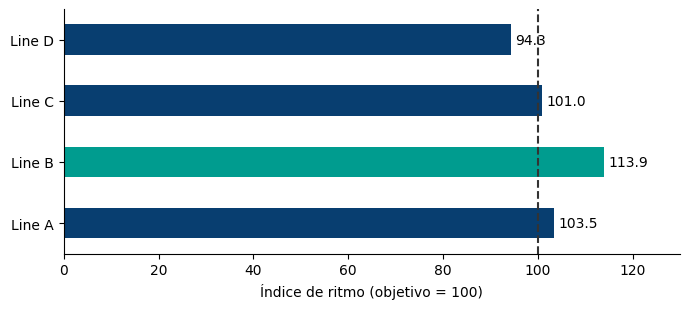

In [7]:
datos["horas_objetivo"] = datos["units_produced"] * datos["target_cycle_min"] / 60
plt.rcParams.update({"figure.figsize": (7, 3.2), "axes.spines.top": False, "axes.spines.right": False})
lineas = datos.groupby("production_line")[["horas_objetivo", "runtime_hours"]].sum()
ritmo = 100 * lineas["horas_objetivo"] / lineas["runtime_hours"]
ax = ritmo.plot.barh(color=["#083e70", "#009c8f", "#083e70", "#083e70"], xlabel="Índice de ritmo (objetivo = 100)", ylabel="")
ax.axvline(100, color="#333333", linestyle="--")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_xlim(0, 130)
plt.tight_layout()
plt.show()

B alcanza **114,0** frente a **94,3** en D. El índice pondera el trabajo de cada lote por su ciclo objetivo. Para decidir dónde intervenir falta incorporar el tiempo perdido en paradas.

## 2 · ¿Cuánto tiempo pierde cada línea en paradas?

El ritmo anterior usa solo las horas activas. Ahora miro cuánto paro acumula un lote típico y hasta dónde llegan los valores más altos.

In [8]:
print(datos["downtime_minutes"].describe(percentiles=[0.5, 0.95, 0.99]).round(1))
print(datos.nlargest(1, "downtime_minutes")[["run_id", "runtime_hours", "downtime_minutes"]].to_string(index=False))

count    9000.0
mean       19.8
std        42.9
min         0.0
50%        11.0
95%        47.0
99%       276.0
max       659.0
Name: downtime_minutes, dtype: float64
run_id  runtime_hours  downtime_minutes
R00801           3.91               659


Leo la fila `50%` así: en al menos la mitad de los 9.000 lotes, el tiempo de paro fue de **11 minutos o menos**. En la fila `95%`, el límite sube a **47 minutos**. El máximo corresponde al lote R00801: **659 minutos**, casi 11 horas. El diccionario indica que un lote puede abarcar varios turnos y que el paro se suma al tiempo activo. Para este lote son 3,91 h activas + 659/60 h de paro ≈ **14,89 h de lote**. El registro permite varias paradas dentro de ese intervalo.

Para identificar dónde se pierde tiempo, elijo **120 minutos acumulados por lote** como umbral de revisión. Es una decisión de análisis: queda entre los percentiles 95 y 99. Para cada línea sumo las horas de paro de cada grupo y las divido por todas las horas de lote de esa línea. Así, si una línea dedica 8 de cada 100 horas a paradas, su barra llega al 8 %.

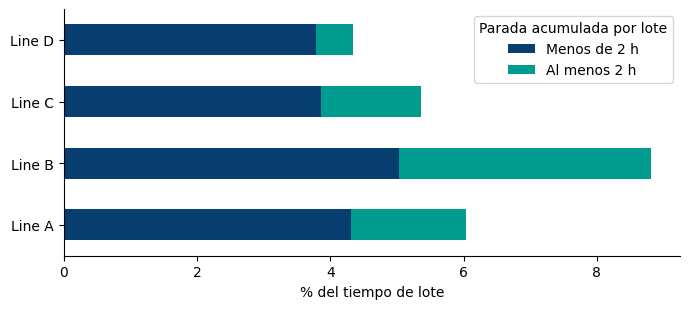

              size     sum
tramo                     
Al menos 2 h   210   938.1
Menos de 2 h  8790  2024.6
production_line
Line A    6.03
Line B    8.81
Line C    5.36
Line D    4.34
dtype: float64


In [9]:
datos["horas_paro"] = datos["downtime_minutes"] / 60
datos["horas_lote"] = datos["runtime_hours"] + datos["horas_paro"]
horas_por_linea = datos.groupby("production_line")["horas_lote"].sum()
datos["tramo"] = datos["downtime_minutes"].ge(120).map({True: "Al menos 2 h", False: "Menos de 2 h"})
horas = datos.groupby(["production_line", "tramo"])["horas_paro"].sum().unstack()
perdida = horas.div(horas_por_linea, axis=0) * 100
ax = perdida[["Menos de 2 h", "Al menos 2 h"]].plot.barh(stacked=True, color=["#083e70", "#009c8f"],
                                                       xlabel="% del tiempo de lote", ylabel="")
ax.legend(title="Parada acumulada por lote")
plt.tight_layout()
plt.show()
print(datos.groupby("tramo")["horas_paro"].agg(["size", "sum"]).round(1))
print(perdida.sum(axis=1).round(2))

B pierde **8,81 %** de su tiempo de lote frente al **6,03 %** de A. En toda la fábrica, **210 de 9.000 lotes** acumulan al menos dos horas de paro y reúnen **938 de 2.963 horas** perdidas (31,7 %).

## 3 · ¿Qué cuesta el correctivo y qué relación tiene con las paradas?

B tiene la mayor proporción de paro. Como Ingeniero en Mecatrónica, distinguiría dos tiempos que aquí se registran por separado. El lote indica cuánto tiempo se perdió durante la producción. El parte indica cuánto duró la intervención en la máquina. Antes de proponer cambios en mantenimiento, quiero saber cuánto cuesta una intervención de cada tipo, cuánto dura y si las máquinas con más correctivos también pierden más tiempo dentro de sus lotes.

In [10]:
print(mantenimiento.groupby("maintenance_type").size().rename("intervenciones"))
print(mantenimiento[["machine_id", "maintenance_type", "maintenance_cost_eur"]].head(3).to_string(index=False))

maintenance_type
Corrective    178
Preventive    338
Name: intervenciones, dtype: int64
machine_id maintenance_type  maintenance_cost_eur
      M009       Corrective                998.30
      M021       Corrective               1300.88
      M008       Corrective               1405.13


Hay 178 intervenciones correctivas y 338 preventivas. Comparo coste y duración *por intervención* para tener en cuenta esa diferencia de frecuencia. Luego sumo los euros por línea para localizar el gasto.

In [11]:
resumen = mantenimiento.groupby("maintenance_type").agg(
    partes=("maintenance_id", "size"),
    euros_totales=("maintenance_cost_eur", "sum"),
    euros_por_parte=("maintenance_cost_eur", "mean"),
    horas_por_parte=("duration_hours", "mean"))
print(resumen.round(2).to_string())

                  partes  euros_totales  euros_por_parte  horas_por_parte
maintenance_type                                                         
Corrective           178      237618.95          1334.94             6.18
Preventive           338      174565.83           516.47             3.39


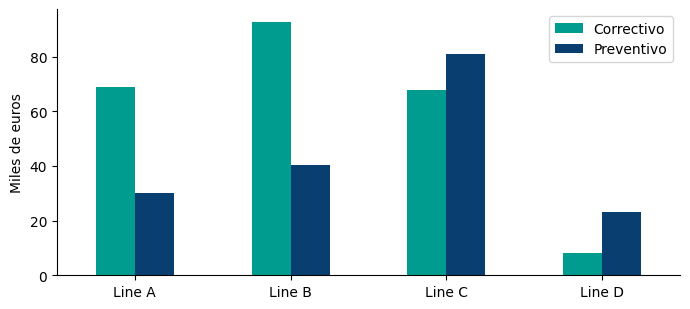

maintenance_type  Corrective  Preventive
production_line                         
Line A               68730.0     29936.0
Line B               92817.0     40527.0
Line C               67905.0     80908.0
Line D                8167.0     23195.0


In [12]:
intervenciones = mantenimiento.merge(maquinas, on="machine_id", validate="m:1")
gasto = intervenciones.groupby(["production_line", "maintenance_type"])["maintenance_cost_eur"].sum().unstack()
ax = (gasto / 1000).rename(columns={"Corrective": "Correctivo", "Preventive": "Preventivo"}).plot.bar(
    color=["#009c8f", "#083e70"], rot=0, xlabel="", ylabel="Miles de euros")
ax.legend(title="")
plt.tight_layout()
plt.show()
print(gasto.round(0))

Un correctivo cuesta en promedio **1.335 €** y dura **6,18 h**. Un preventivo cuesta **516 €** y dura **3,39 h**. El correctivo cuesta **2,6 veces más por intervención** y suma **237.619 €** en el año, aunque hay casi la mitad de partes. B concentra **92.817 €** de ese gasto.

**¿Aparece también más paro en las máquinas con más correctivos?** Agrupo los partes por máquina y calculo correctivos por 1.000 horas de lote. Divido las 36 máquinas en dos grupos según la mediana de esa frecuencia. Dentro de cada grupo comparo las horas de paro por 100 horas de lote.

In [13]:
por_maquina = datos.groupby("machine_id")[["horas_paro", "horas_lote"]].sum()
correctivos = mantenimiento.loc[mantenimiento["maintenance_type"] == "Corrective"]
partes = correctivos.groupby("machine_id").size().reindex(por_maquina.index, fill_value=0)
frecuencia = 1000 * partes / por_maquina["horas_lote"]
por_maquina["grupo"] = (frecuencia > frecuencia.median()).map(
    {True: "Mayor frecuencia", False: "Menor frecuencia"})
grupos = por_maquina.groupby("grupo").agg(maquinas=("horas_lote", "size"),
                                         paro=("horas_paro", "sum"), total=("horas_lote", "sum"))
grupos["paro_por_100_h"] = 100 * grupos["paro"] / grupos["total"]
print("Mediana de correctivos por 1.000 horas de lote:", round(frecuencia.median(), 2))
print(grupos[["maquinas", "paro_por_100_h"]].round(2))

Mediana de correctivos por 1.000 horas de lote: 3.37
                  maquinas  paro_por_100_h
grupo                                     
Mayor frecuencia        18            7.24
Menor frecuencia        18            5.29


Las 18 máquinas con mayor frecuencia de correctivos pierden **7,24 horas por cada 100 horas de lote**. Las otras 18 pierden **5,29 horas**. La diferencia de **1,95 horas por cada 100** respalda mi sospecha de que ambos problemas coinciden. Una avería recurrente podría explicar tanto los paros como las reparaciones. Los partes de mantenimiento ocurren fuera de los lotes y falta un identificador de avería que los vincule a cada parada. Por eso mediría las dos duraciones por separado.

## 4 · ¿Cómo cambia la calidad con la complejidad del producto?

Paso de la máquina al producto. Compruebo qué niveles de complejidad hay y qué parte de cada lote llega a inspección.

In [14]:
print(productos.groupby("complexity_level").size().rename("productos"))
print(datos[["run_id", "units_produced", "units_inspected", "defective_units"]].head(3).to_string(index=False))

complexity_level
High      10
Low        7
Medium    13
Name: productos, dtype: int64
run_id  units_produced  units_inspected  defective_units
R00001             218               75                1
R00002             173               32                1
R00003             418               82                2


La inspección examina una muestra de cada lote. Para comparar los tres niveles, sumo las unidades defectuosas y las inspeccionadas dentro de cada nivel. Divido el primer total entre el segundo y multiplico por 100.

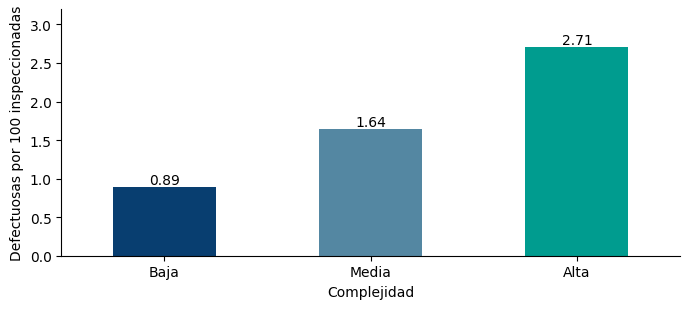

                  defective_units  units_inspected
complexity_level                                  
Low                          1084           121205
Medium                       3995           243897
High                         4775           176448


In [15]:
calidad = datos.groupby("complexity_level")[["defective_units", "units_inspected"]].sum().reindex(["Low", "Medium", "High"])
tasa = 100 * calidad["defective_units"] / calidad["units_inspected"]
ax = tasa.rename(index={"Low": "Baja", "Medium": "Media", "High": "Alta"}).plot.bar(
    rot=0, color=["#083e70", "#5487a2", "#009c8f"], xlabel="Complejidad", ylabel="Defectuosas por 100 inspeccionadas")
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set_ylim(0, 3.2)
plt.tight_layout()
plt.show()
print(calidad)

La tasa pasa de **0,89 %** a **1,64 %** y **2,71 %**. Dado que inspección toma muestras, las cifras describen las unidades inspeccionadas. Esto importa al evaluar turnos que reciben productos de distinta complejidad.

## 5 · ¿Reciben los turnos trabajos comparables?

La complejidad está asociada con los defectos observados. Antes de comparar mañana, tarde y noche, miro qué proporción de la muestra de cada turno corresponde a cada complejidad.

In [16]:
mezcla = datos.groupby(["shift", "complexity_level"])["units_inspected"].sum().unstack()
print((100 * mezcla.div(mezcla.sum(axis=1), axis=0)).round(1))

complexity_level  High   Low  Medium
shift                               
Evening           32.5  21.7    45.7
Morning           27.4  27.0    45.6
Night             43.6  13.7    42.7


La complejidad alta representa cerca del 44 % de la muestra nocturna y del 27 % de la matinal. ¿Cuánto cambia la diferencia entre ambos turnos si les damos la misma mezcla? Primero calculo la tasa observada por turno. Después calculo las tasas por turno y complejidad y las pondero con la distribución de complejidad de toda la muestra anual.

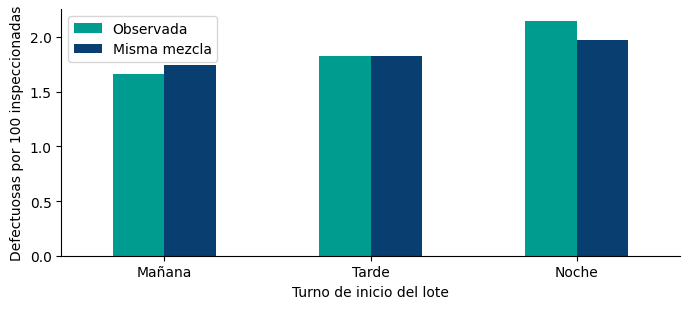

        Observada  Misma mezcla
shift                          
Mañana       1.66          1.75
Tarde        1.83          1.82
Noche        2.15          1.97


In [17]:
muestra = datos.groupby(["shift", "complexity_level"])[["defective_units", "units_inspected"]].sum()
por_turno = muestra.groupby(level="shift").sum()
observada = 100 * por_turno["defective_units"] / por_turno["units_inspected"]
por_nivel = (100 * muestra["defective_units"] / muestra["units_inspected"]).unstack()
pesos = calidad["units_inspected"] / calidad["units_inspected"].sum()
comparacion = pd.DataFrame({"Observada": observada, "Misma mezcla": por_nivel.mul(pesos).sum(axis=1)})
comparacion = comparacion.reindex(["Morning", "Evening", "Night"]).rename(index={"Morning": "Mañana", "Evening": "Tarde", "Night": "Noche"})
ax = comparacion.plot.bar(rot=0, color=["#009c8f", "#083e70"], xlabel="Turno de inicio del lote", ylabel="Defectuosas por 100 inspeccionadas")
ax.legend(title="")
plt.tight_layout()
plt.show()
print(comparacion.round(2))

La brecha noche–mañana pasa de **0,49 a 0,22 puntos porcentuales** al igualar la mezcla de complejidad. La diferencia residual puede incluir producto, máquina o condiciones del proceso. El turno identifica cuándo arrancó el lote, y la inspección no indica en qué momento surgió el defecto.

## Dos acciones para operaciones y sus limitaciones

### 1. Fiabilidad | Ensayar una tarea preventiva en la línea B

B pierde el **8,81 %** de sus horas de lote y acumula **92.817 €** de correctivo. Empezaría aquí por el coste y el tiempo en juego. Para elegir la tarea preventiva necesito conocer primero qué avería se repite.

**Cómo lo haría**

1. Revisaría los lotes de B con **120 minutos o más de paro acumulado**. En los siguientes lotes registraría por episodio la máquina, la hora, la duración, la causa y, cuando exista, la orden de trabajo.
2. Agruparía los episodios por causa y sumaría sus horas. Con mantenimiento elegiría una avería recurrente que admita prevención y ensayaría una tarea dirigida a esa causa.
3. Compararía, antes y durante el piloto, las **horas de paro por cada 100 horas de lote** en las mismas máquinas y con productos comparables. Para decidir si ampliar el piloto, contrastaría la reducción observada con el coste y las horas adicionales de preventivo.

**Limitación.** Los CSV relacionan lotes e intervenciones por máquina. Falta el vínculo entre cada parada y su avería. El gasto anual permite elegir dónde investigar, pero estimar un ahorro exige conocer qué episodios habría evitado la tarea propuesta.

### 2. Calidad | Probar una verificación de arranque en productos de complejidad alta

En las muestras inspeccionadas, la tasa de defectos pasa del **0,89 %** en complejidad baja al **2,71 %** en alta. Empezaría por esos productos. La brecha noche–mañana baja de **0,49 a 0,22 puntos porcentuales** cuando ambos turnos se comparan con la misma mezcla de complejidad.

**Cómo lo haría**

1. Seleccionaría lotes del mismo producto de complejidad alta fabricados en la misma máquina. Dentro de cada turno repartiría al azar los lotes entre el procedimiento habitual y una verificación adicional de la primera pieza.
2. Mantendría el mismo criterio de muestreo e inspección en ambos grupos. Registraría cuántas unidades se inspeccionaron, cuántas resultaron defectuosas y cuánto tiempo añadió la verificación.
3. Para cada grupo calcularía **100 × total de defectuosas / total de inspeccionadas**. Antes de extender la verificación, evaluaría si la diferencia observada se repite en otros lotes y justifica el tiempo de arranque adicional.

**Limitación.** La inspección cubre una muestra y el turno corresponde al inicio del lote. Los registros de 2025 tampoco indican en qué fase apareció el defecto. La mayor tasa señala dónde probar la verificación de arranque. Su eficacia queda pendiente de medir en el piloto.